In [ ]:
from scipy.optimize import curve_fit
import numpy as np
import math
from matplotlib import pyplot as plt
import pandas as pd
np.set_printoptions(precision=3)

class Gaussian:
    """Gaussian function"""
    def __init__(self, width, amplitude, x0):
        """Create Gaussian with the given width and amplitude, centered at x = x0"""
        self.width = width
        self.amplitude = amplitude
        self.x0 = x0

    def __call__(self, x):
        return self.amplitude * np.exp(-((x - self.x0) ** 2) / (2 * self.width ** 2))

In [ ]:
# Constants of the laser beam

lmd = 500e-9 # 500 nm
k_0 = 2*np.pi/lmd
wf = 1e-2 # 1 cm
P0 = 1e-2 # 10 mW
Ef = 1/wf*np.sqrt(2*P0/math.pi)
zf = k_0*wf**2/2
print('Amplitude of the electromagnetic field at origin (z=0):',Ef, "sqrt(W/m2)")
print("Rayleigh length:", zf, 'm')
J, N = 300, 1000

def analytical(r,z):
    wz = wf*np.sqrt(1+(z/zf)**2)
    temp = Ef*wf/wz*np.exp(-r**2/wz**2)
    return np.abs(temp)**2

Amplitude of the electromagnetic field at origin (z=0): 7.978845608028654 sqrt(W/m2)
Rayleigh length: 628.3185307179588 m


In [ ]:
class CrankNicolson:
    def __init__(self, L, J, T, N, a0, r):

        # initialise spatial grid where J is the number of spatial grid points
        self.L = L # the unit length of the domain
        self.J = J
        self.dx = float(self.L)/float(self.J-1)
        self.x_grid = np.array([j*self.dx for j in range(self.J)])

        # initialise the temporal grid where T the length of the time domain and N
        self.T = T
        self.N = N
        self.dt = float(T)/float(N-1)
        self.t_grid = np.array([n*self.dt for n in range(N)])
        self.xc = r*self.L
        self.a0=a0

    def set_parameters(self, D):
        self.D = D

    def matrices(self): # implement without the Neumann boundary conditions
        sigma, nu = self.D*self.dt/(2*self.dx**2), self.V*self.dt/(4*self.dx)

        self.sigma = sigma
        self.nu = nu

        self.A = np.diagflat([-(sigma+nu) for i in range(self.J-1)], -1) +\
        np.diagflat([1.+2.*sigma for i in range(self.J)]) +\
        np.diagflat([-(sigma-nu) for i in range(self.J-1)], 1)

        self.B = np.diagflat([(sigma+nu) for i in range(self.J-1)], -1) +\
        np.diagflat([1.-2.*sigma + 1j*self.dt*(1-j**2*self.dx**2) for j in range(self.J)]) +\
        np.diagflat([(sigma-nu) for i in range(self.J-1)], 1)

        return self.A, self.B

    def modify(self): # boundary conditions implemented
        sigma = self.D*self.dt/(2*self.dx**2)
        self.sigma=sigma
        xc=self.xc
        dx=self.dx

        self.A = np.diagflat([-(sigma*(1-1/(2*i))) for i in range(1,self.J-1)]+[-4*sigma], -1) +\
        np.diagflat([(1.+4.*sigma)]+[1.+2.*sigma - self.dt*(1j*(1-(i*self.dx)**2)/2 + \
        0*self.a0*np.heaviside((i*dx-xc), 0.5)*(i*dx-xc)**2) for i in range(1,self.J-1)]+[(1.+4.*sigma)]) +\
        np.diagflat([-4*sigma]+[-(sigma*(1+1/(2*i))) for i in range(1,self.J-1)], 1)

        self.B = np.diagflat([(sigma*(1-1/(2*i))) for i in range(1,self.J-1)]+[4*sigma], -1) +\
        np.diagflat([1.-4.*sigma]+[1.-2.*sigma + self.dt*(1j*(1-(i*self.dx)**2)/2 - \
        0*self.a0*np.heaviside((i*dx-xc), 0.5)*(i*dx-xc)**2) for i in range(1,self.J-1)]+[1.-4.*sigma]) +\
        np.diagflat([4*sigma]+[(sigma*(1+1/(2*i))) for i in range(1,self.J-1)], 1)

        return self.A, self.B

    def solve(self, A, B, U0):
        xc=self.xc
        dx=self.dx
        sol = [U0,U0]
        Un, Un_1 = U0, U0 # initial values
        for n in range(1, self.N-1): # already have U0 and U1, need N-1 more steps
            rhs = B.dot(Un)
            Un_1 = Un
            Un = np.linalg.solve(A, rhs)
            Un *= np.exp([0]+[-self.a0*np.heaviside((i*dx-xc), 0.5)*(i*dx-xc)**2 for i in range(1,self.J)])
            sol.append(Un)
        return sol


In [ ]:
def x(z_tilda, xi): # translates xi to x_tilda at z_tilda
    return xi*np.sqrt(1+(z_tilda**2/zf**2))*wf

def translate(z_tilda, s, crank):
    z = z_tilda/zf
    zeta = np.arctan(z)
    j = int(zeta/crank.dt)
    print(j, len(s))
    C = s[j]

    # translating to r_tilda and z
    E = 1/np.sqrt(1+z**2)*np.array([np.exp(1j*((i*crank.dx)**2*(1+z**2)/(z+1/z)-zeta)) for i in range(crank.J)]) # make this i*self.dx

    # translating to physical variable
    a = Ef*E

    return np.abs(C*a)**2

### Random noise

0.3184669270777387 0.3184669270777387


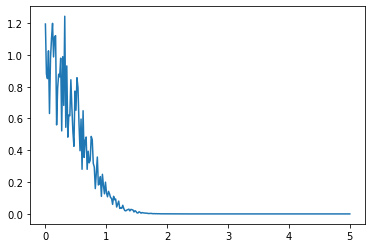

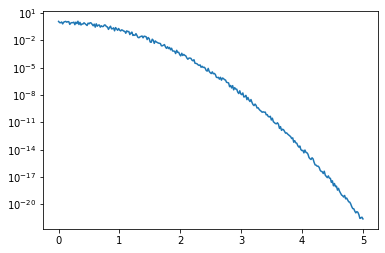

In [ ]:
distance = 384400e3
#distance = 20000

J = 300

xi_size, zeta_max = 5, np.arctan(distance/zf)

sigma, x0, U_0 = 1/np.sqrt(2), 0, 1 # since our initial condition is exp(-xi**2)
gaussian_function = Gaussian(sigma, U_0, x0)
crank_noise = CrankNicolson(xi_size, J, zeta_max, N, a0, r)

a0, r = 0.1, 0.2
z = 20000
print(wf*np.sqrt(1+(z/zf)**2), x(z, xi_size*r))
# Set parameters
D = 1j/4

#crank_noise.set_parameters(D)
crank_noise.set_parameters(D)

# Compute matrices A and B
A, B = crank_noise.modify()


# Initial condition given by U0
U0_noise = gaussian_function(crank_noise.x_grid)*(1 + (np.random.rand(J)-0.5)*0.5)

noise = U0_noise -gaussian_function(crank_noise.x_grid)


# Plot initial condition
plt.plot(crank_noise.x_grid, np.abs(U0_noise)**2)
plt.show()

plt.semilogy(crank_noise.x_grid, np.abs(U0_noise)**2)
plt.show()

# Solve the system of equations
s = crank_noise.solve(A, B, U0_noise)

[[1.194e+00 8.788e-01 8.505e-01 ... 3.301e-22 4.039e-22 2.593e-22]
 [1.194e+00 8.788e-01 8.505e-01 ... 3.301e-22 4.039e-22 2.593e-22]
 [7.173e-01 9.237e-01 9.102e-01 ... 1.498e-23 1.157e-23 1.694e-23]
 ...
 [6.392e-01 8.092e-01 8.478e-01 ... 5.234e-82 2.030e-82 1.882e-82]
 [8.595e-01 8.011e-01 7.877e-01 ... 5.236e-82 2.031e-82 1.882e-82]
 [9.425e-01 7.926e-01 7.748e-01 ... 5.239e-82 2.032e-82 1.883e-82]]


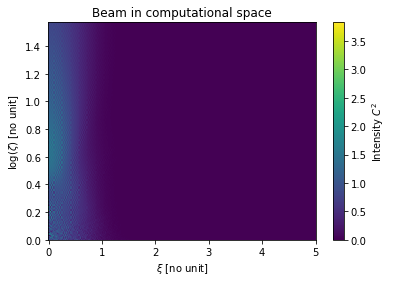

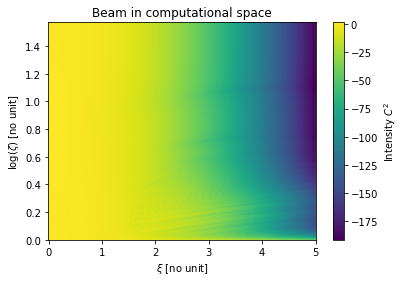

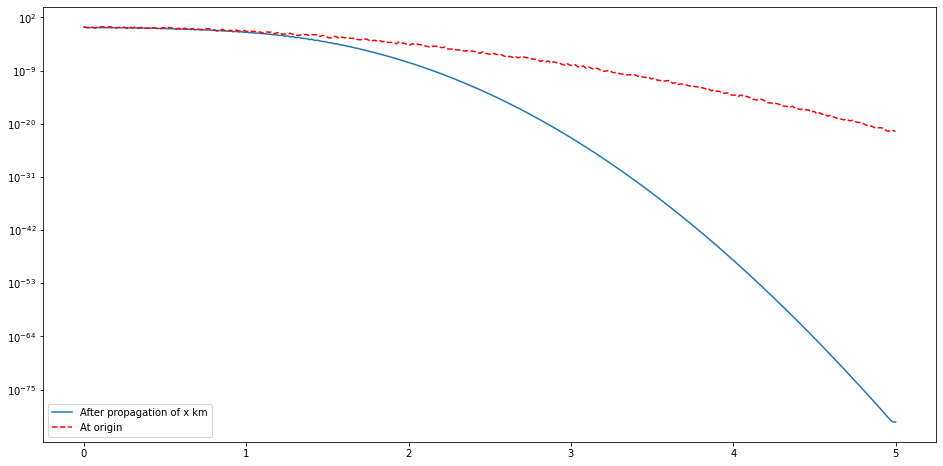

In [ ]:
solution_noise = np.abs(s)**2

print(solution_noise)
# Plot the solution
def plot_solution(solution, x_grid, t_grid):
    plt.pcolormesh(x_grid, t_grid, solution)
    plt.xlabel(r'$\xi$ [no unit]')
    plt.ylabel('log($\zeta$) [no unit]')
    plt.colorbar(label=r'Intensity $C^2$')
    plt.title('Beam in computational space')
    plt.savefig("Random, color.png", dpi = 500)
    plt.show()

plot_solution(solution_noise, crank_noise.x_grid, crank_noise.t_grid)

plot_solution(np.log(solution_noise), crank_noise.x_grid, crank_noise.t_grid)

plt.figure(figsize=(16, 8))
plt.semilogy(crank_noise.x_grid, solution_noise[-1], label='After propagation of x km')
plt.semilogy(crank_noise.x_grid, np.abs(U0_noise)**2,'r', linestyle='--', label = 'At origin')
plt.legend(loc='lower left')
plt.show()

999 1000


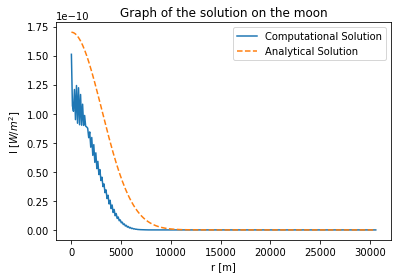

979 1000


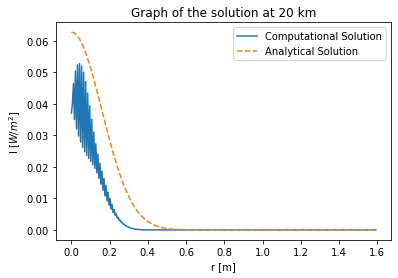

0 1000


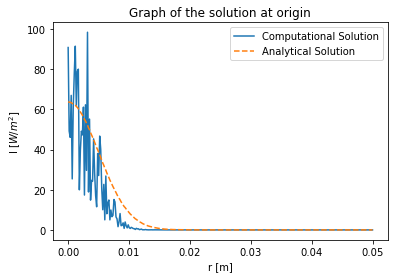

In [ ]:
# Plot after dist km

dist = 384400e3
x_grid = np.array([j*(max(x(dist, crank_noise.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, crank_noise.x_grid), translate(dist, solution_noise, crank_noise), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, dist), linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution on the moon')
plt.legend()
plt.savefig("Random, Moon, 1cm, 10mW, Compu.png", dpi = 1000)
plt.show()


dist = 20000
x_grid = np.array([j*(max(x(dist, crank_noise.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, crank_noise.x_grid), translate(dist, solution_noise, crank_noise), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, dist), linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution at 20 km')
plt.legend()
plt.savefig("Random, 20km, 1cm, 10mW, Compu.png", dpi = 1000)
plt.show()


# Plot for the initial condition
dist = 0.0000000001
x_grid = np.array([j*(max(x(dist, crank_noise.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, crank_noise.x_grid), translate(dist, solution_noise, crank_noise), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, 0)+noise, linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution at origin')
plt.legend()
plt.savefig("Random, Origin, 1cm, 10mW, Compu.png", dpi = 1000)
plt.show()

### Square function
We know the solution for the square function.

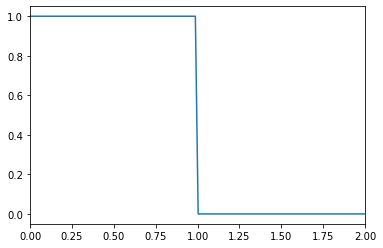

In [ ]:
import sys # so we don't divide by zero

distance = 20000
J = 300

xi_size, zeta_max = 5, np.arctan(distance/zf)
sigma, x0, U_0 = 1/np.sqrt(2), 0, 1 # since our initial condition is exp(-xi**2)
gaussian_function = Gaussian(sigma, U_0, x0)
crank_square = CrankNicolson(xi_size, J, zeta_max, N, a0, r)

crank_square.set_parameters(D)

A, B = crank_square.modify()

def square_function(x):
    return np.where(np.abs(x) <= 1, 1, 0)

# Initial condition given by U0
U0 = square_function(crank_square.x_grid)

# Plot initial condition
plt.plot(crank_square.x_grid, np.abs(U0)**2)
plt.xlim(0,2)
plt.show()

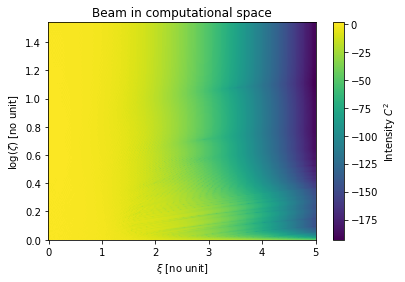

In [ ]:
s = crank_square.solve(A, B, U0_noise)
sol_squ = np.abs(s)**2

# Plot the solution
# Plot the solution
def plot_solution_sq(solution, x_grid, t_grid):
    plt.pcolormesh(x_grid, t_grid, solution)
    plt.xlabel(r'$\xi$ [no unit]')
    plt.ylabel('log($\zeta$) [no unit]')
    plt.colorbar(label=r'Intensity $C^2$')
    plt.title('Beam in computational space')
    plt.savefig("Square, color.png", dpi = 500)
    plt.show()

plot_solution_sq(np.log(sol_squ), crank_square.x_grid, crank_square.t_grid)

999 1000


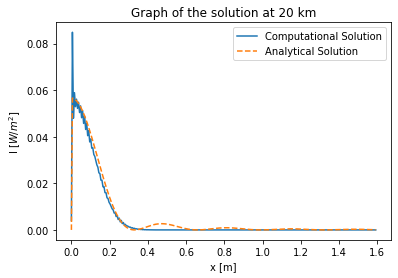

In [ ]:
x_grid = np.array([j*(max(x(dist, crank_square.x_grid))/float(J-1)) for j in range(J)])

ana = 0.025*np.sin(np.pi/0.33*x_grid)/(x_grid+sys.float_info.min)

dist = distance

plt.plot(x(dist, crank_square.x_grid), translate(dist, sol_squ, crank_square), label='Computational Solution')
plt.plot(x_grid, ana**2, linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution at 20 km')
plt.legend()
#plt.savefig("20km, 1cm, 10mW, Compu.png", dpi = 1000)
plt.show()

## Atmospheric effects propagated to the moon

W=0.5m, lambda = 635nm, initial amplitude = 1

In [ ]:
df = pd.read_csv("stuff.csv")

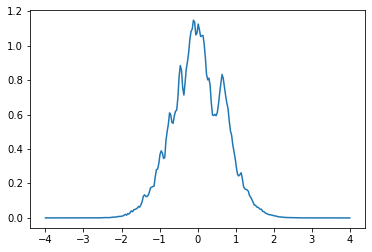

128.0


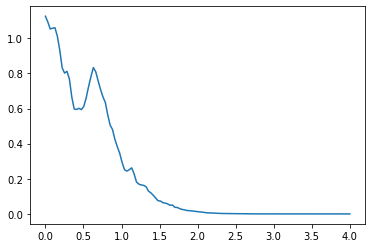

In [ ]:
# Extract the 5th row (index 4)
row = df.iloc[127]

# Extract the values
values = row.values

# Convert values to string and remove parentheses
values_str = [complex(str(value).strip('()')) for value in values]

# Print the results
c = len(values_str)
plt.plot(np.linspace(-4,4, c), np.abs(values_str)**2)
plt.show()
print(len(values_str)/2)

# Prepare half of the Gaussian
Ua0 = values_str[128:]
Ub0 = values_str[:128]
plt.plot(np.linspace(0,4, c//2), np.abs(Ua0)**2)
plt.show()

In [ ]:
distance = 384400e3

J = 128
a0, r = 0.1, 0.20001

lmd = 635e-9 # 500 nm
k_0 = 2*np.pi/lmd
wf = 0.5 # 1 cm
Ef = 1
P0 = math.pi*(Ef*wf)**2/2

zf = k_0*wf**2/2

z = 384400e3

xi_size, zeta_max = 5, np.arctan(distance/zf)
sigma, x0, U_0 = 1/np.sqrt(2), 0, 1 # since our initial condition is exp(-xi**2)
gaussian_function = Gaussian(sigma, U_0, x0)
atmos = CrankNicolson(xi_size, J, zeta_max, N, a0, r)

print(wf*np.sqrt(1+(z/zf)**2), x(z, xi_size*r))


atmos.set_parameters(D)

A, B = atmos.modify()

155.3958711155511 155.40364090910685


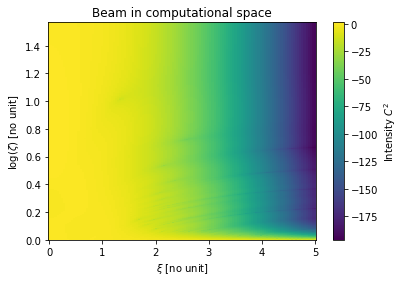

In [ ]:
s = atmos.solve(A, B, Ua0)
sol_atmos = np.abs(s)**2

# Plot the solution
def plot_solution_atmos(solution, x_grid, t_grid):
    plt.pcolormesh(x_grid, t_grid, solution)
    plt.xlabel(r'$\xi$ [no unit]')
    plt.ylabel('log($\zeta$) [no unit]')
    plt.colorbar(label=r'Intensity $C^2$')
    plt.title('Beam in computational space')
    plt.savefig("Atm, color.png", dpi = 500)
    plt.show()

#plot_solution_atmos(sol_atmos, atmos.x_grid, atmos.t_grid)
plot_solution_atmos(np.log(sol_atmos), atmos.x_grid, atmos.t_grid)


In [ ]:
# Reimplement translate

def x(z_tilda, xi): # translates xi to x_tilda at z_tilda
    return xi*np.sqrt(1+(z_tilda**2/zf**2))*wf

def translate(z_tilda, solution, crank):
    z = z_tilda/zf
    zeta = np.arctan(z)
    j = int(zeta/crank.dt)
    C = s[j]

    # translating to r_tilda and z
    E = 1/np.sqrt(1+z**2)*np.array([np.exp(1j*((i*crank.dx)**2*(1+z**2)/(z+1/z)-zeta)) for i in range(crank.J)]) # make this i*self.dx

    # translating to physical variable
    a = Ef*E

    return np.abs(C*a)**2

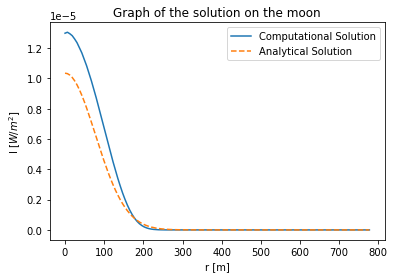

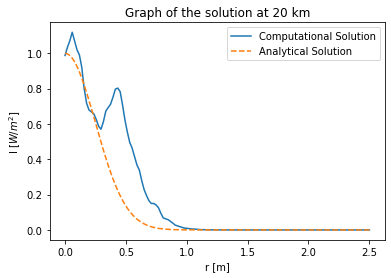

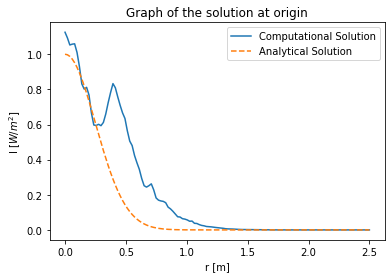

In [ ]:
# Plot after dist km
dist = 384400e3
x_grid = np.array([j*(max(x(dist, atmos.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, atmos.x_grid), translate(dist, sol_atmos, atmos), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, dist), linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution on the moon')
plt.legend()
plt.savefig("Atm, Moon, 1cm, 10mW, Compu.png", dpi = 500)
plt.show()


dist = 20000
x_grid = np.array([j*(max(x(dist, atmos.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, atmos.x_grid), translate(dist, sol_atmos, atmos), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, dist), linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution at 20 km')
plt.legend()
plt.savefig("Atm, 20km, 1cm, 10mW, Compu.png", dpi = 500)
plt.show()


# Plot for the initial condition
dist = 0.0000000001
x_grid = np.array([j*(max(x(dist, atmos.x_grid))/float(J-1)) for j in range(J)])

plt.plot(x(dist, atmos.x_grid), translate(dist, sol_atmos, atmos), label='Computational Solution')
plt.plot(x_grid, analytical(x_grid, 0), linestyle='--', label='Analytical Solution')
plt.xlabel('r [m]')
plt.ylabel('I [$W/m^2$]')
plt.title('Graph of the solution at origin')
plt.legend()
plt.savefig("Atm, Origin, 1cm, 10mW, Compu.png", dpi = 500)
plt.show()